In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/processed/cleaned_customer_churn.csv"
)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.shape

(7043, 21)

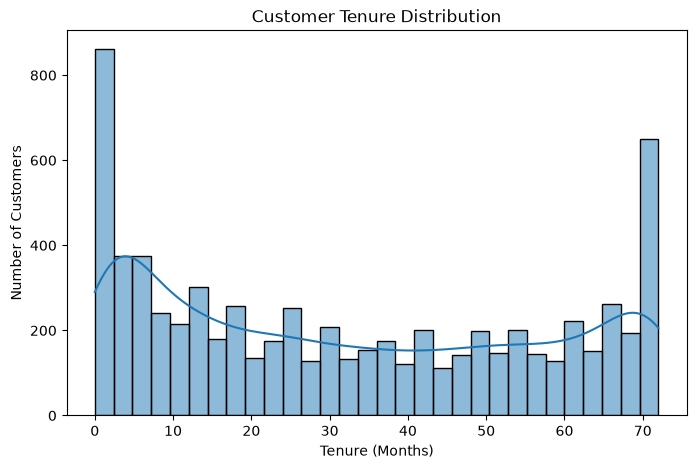

In [3]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="tenure", bins=30, kde=True)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

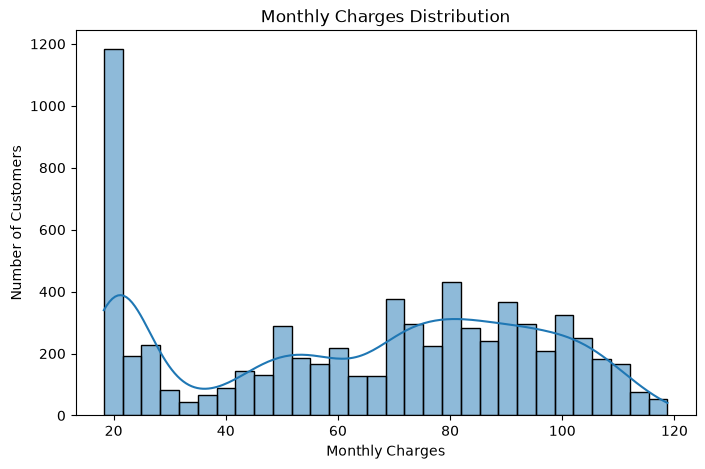

In [4]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="MonthlyCharges", bins=30, kde=True)

plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

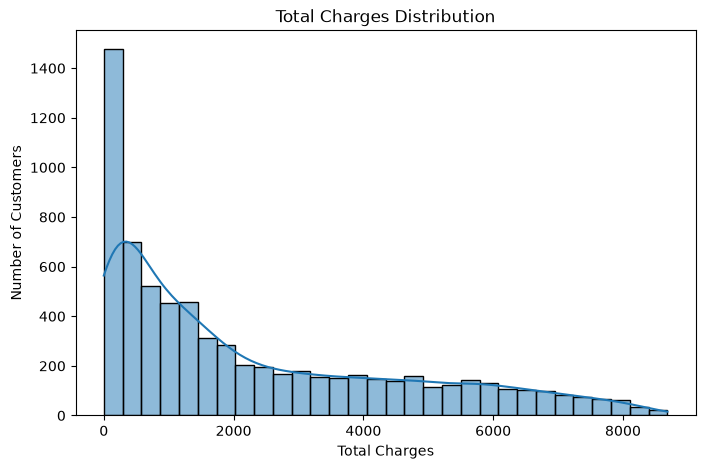

In [5]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="TotalCharges", bins=30, kde=True)

plt.title("Total Charges Distribution")
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")

plt.show()

### Numerical Features: EDA Insights

1. Tenure:
   Customer tenure ranges from 0 to 72 months.
   Higher customer concentration is observed at
   the beginning and end of the tenure range.

2. MonthlyCharges:
   Monthly charges show multiple concentrations,
   indicating different customer spending levels.

3. TotalCharges:
   TotalCharges distribution is right-skewed.
   Most customers have relatively lower accumulated
   charges, while some have higher total charges.

### Business Insights

- Customers have different tenure patterns.
- Monthly spending varies across customers.
- Long-term customers may contribute higher
  accumulated revenue.

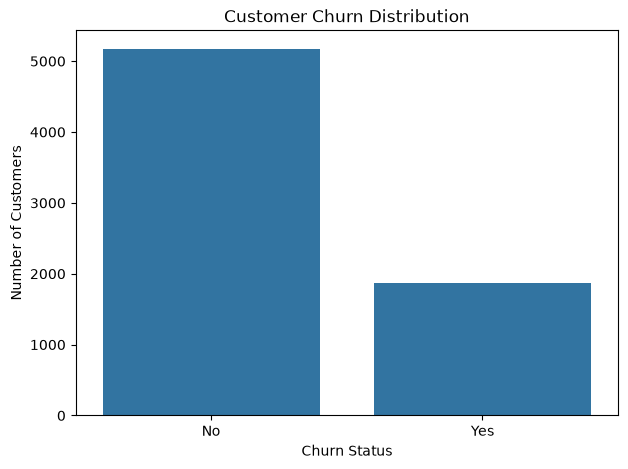

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

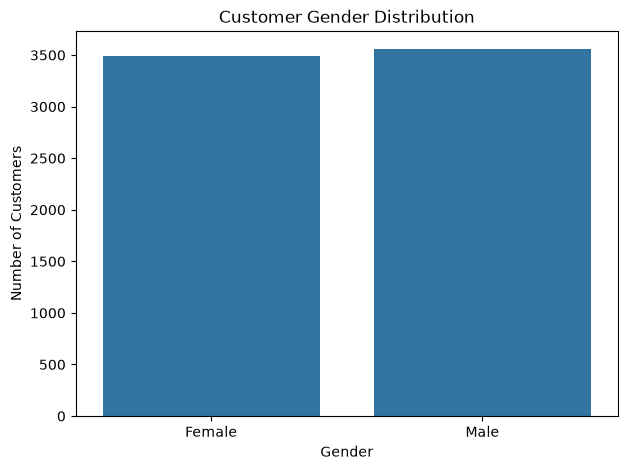

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="gender")

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

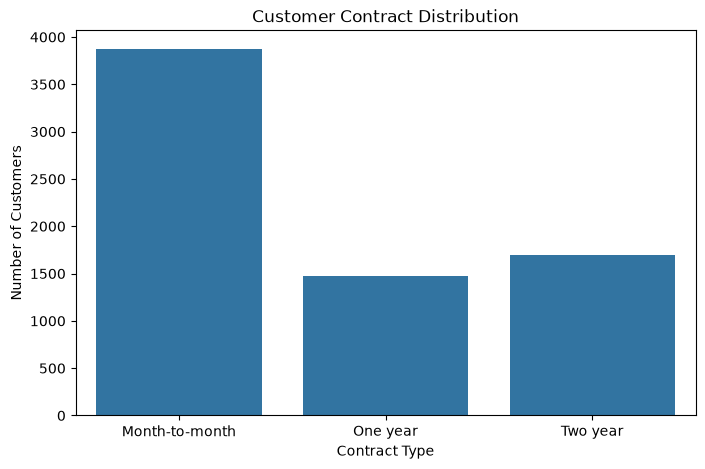

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract")

plt.title("Customer Contract Distribution")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

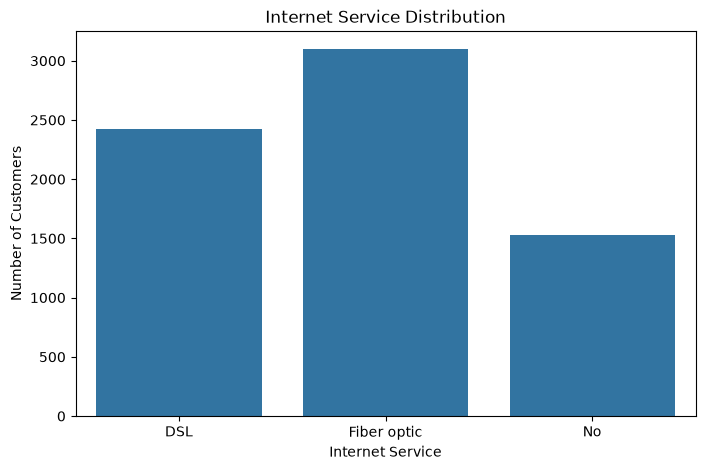

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="InternetService")

plt.title("Internet Service Distribution")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

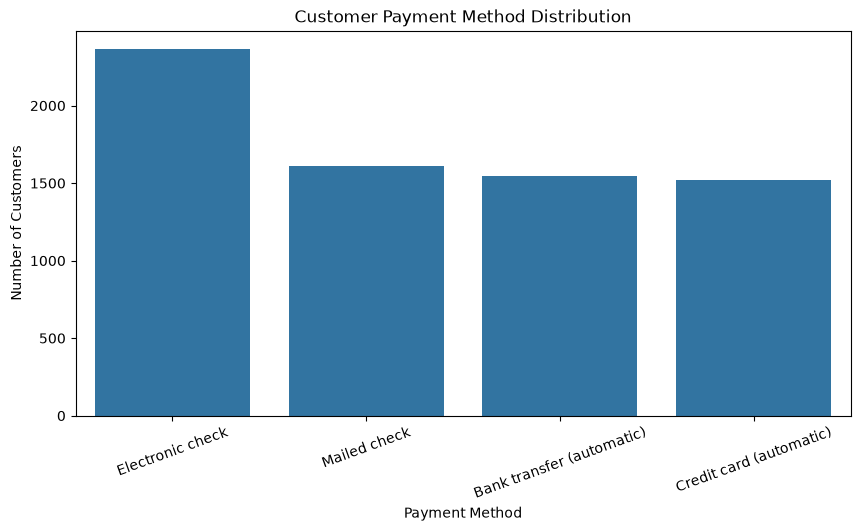

In [10]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="PaymentMethod")

plt.title("Customer Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

### Categorical Univariate Analysis: Key Findings

1. Churn:
   Approximately 26.54% of customers have churned.

2. Gender:
   Male and female customers are nearly equally distributed.

3. Contract:
   Month-to-month contracts are the most common.

4. InternetService:
   Fiber optic is the most frequently used internet service.

5. PaymentMethod:
   Electronic check is the most common payment method.

### Business Interpretation

The dataset shows a significant customer churn problem.
Further analysis is required to identify which customer
groups have higher churn rates.

In [11]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


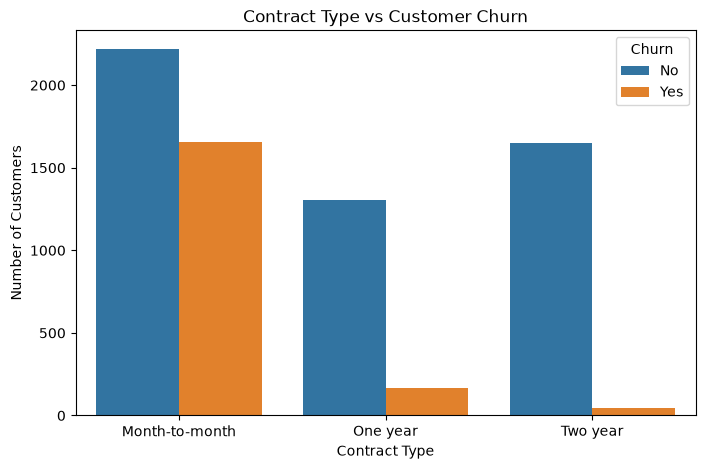

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")

plt.show()

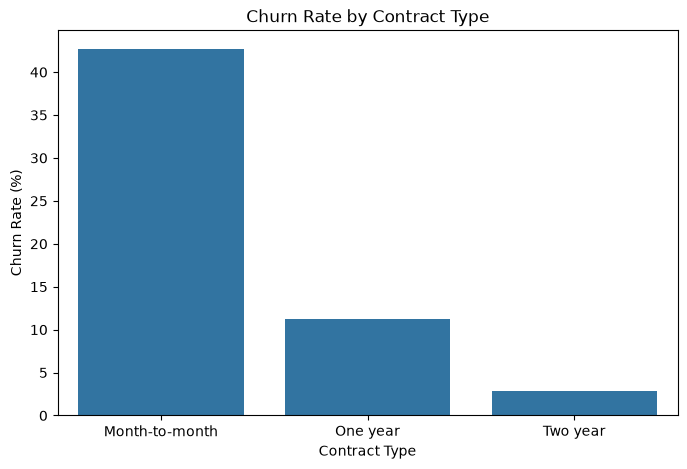

In [13]:
churn_rate = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=churn_rate.index,
    y=churn_rate.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

### Bivariate Analysis: Contract vs Churn

Observations:

1. Month-to-month customers have the highest
   churn rate of 42.71%.

2. One-year contract customers have a churn
   rate of 11.27%.

3. Two-year contract customers have the lowest
   churn rate of 2.83%.

Business Insights:

- Month-to-month customers are a high-priority
  segment for retention strategies.
- Long-term contract customers show lower churn.
- The company can explore long-term contract
  incentives to improve customer retention.

In [14]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn.round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


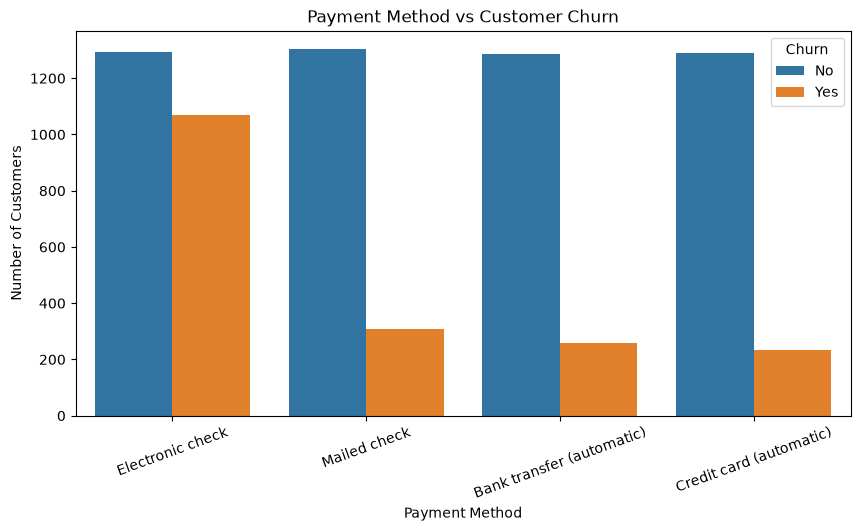

In [15]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Payment Method vs Customer Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)
plt.legend(title="Churn")

plt.show()

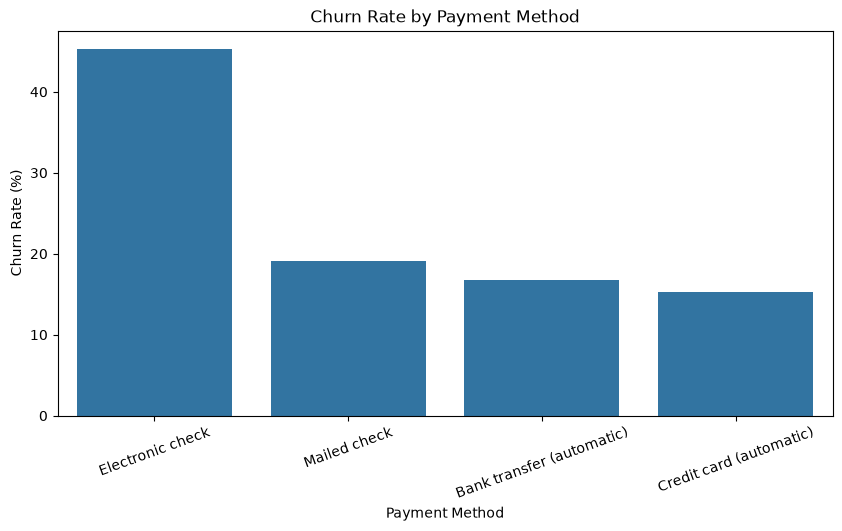

In [16]:
payment_rate = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_rate.index,
    y=payment_rate.values
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=20)

plt.show()

### Bivariate Analysis: Payment Method vs Churn

Observations:

1. Electronic check users have the highest churn
   rate of 45.29%.

2. Mailed check users have a churn rate of 19.11%.

3. Bank transfer users have a churn rate of 16.71%.

4. Credit card users have the lowest churn rate
   of 15.24%.

Business Insights:

- Electronic check users are a high-priority
  segment for churn investigation.
- Automatic payment users show comparatively
  lower churn rates.
- The company can investigate payment experience
  and promote convenient payment options.

In [17]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn.round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


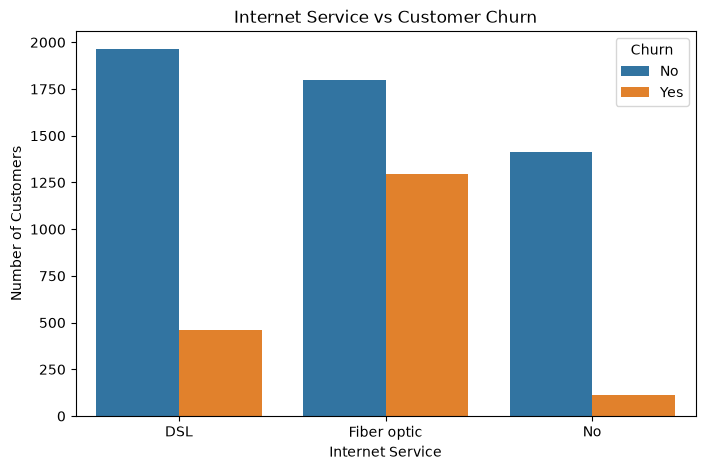

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Internet Service vs Customer Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.legend(title="Churn")

plt.show()

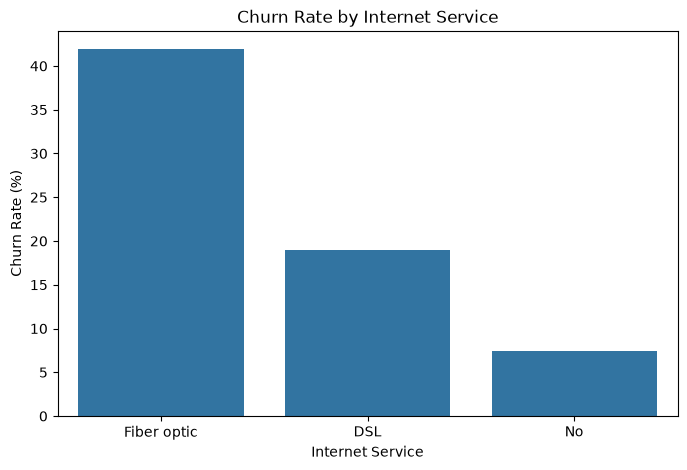

In [19]:
internet_rate = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_rate.index,
    y=internet_rate.values
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.show()

### Bivariate Analysis: Internet Service vs Churn

Observations:

1. Fiber optic customers have the highest churn
   rate of 41.89%.

2. DSL customers have a churn rate of 18.96%.

3. Customers without internet service have the
   lowest churn rate of 7.40%.

Business Insights:

- Fiber optic customers are a high-priority
  segment for churn investigation.
- The company should investigate fiber optic
  service quality and customer experience.
- Internet service type is associated with
  differences in customer churn.

In [20]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)

In [21]:
df["TenureGroup"].value_counts().sort_index()

TenureGroup
0-12 Months     2186
13-24 Months    1024
25-48 Months    1594
49-72 Months    2239
Name: count, dtype: int64

In [22]:
tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

tenure_churn.round(2)

Churn,No,Yes
TenureGroup,,
0-12 Months,52.56,47.44
13-24 Months,71.29,28.71
25-48 Months,79.61,20.39
49-72 Months,90.49,9.51


In [23]:
tenure_rate = (
    df.groupby("TenureGroup", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

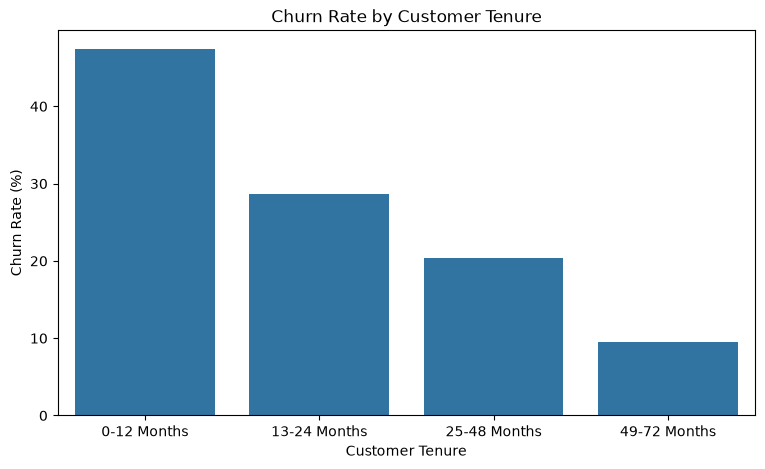

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=tenure_rate.index,
    y=tenure_rate.values
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")

plt.show()

### Bivariate Analysis: Tenure vs Churn

Observations:

1. Customers with 0-12 months tenure have the
   highest churn rate of 47.44%.

2. Customers with 13-24 months tenure have
   a churn rate of 28.71%.

3. Customers with 25-48 months tenure have
   a churn rate of 20.39%.

4. Customers with 49-72 months tenure have
   the lowest churn rate of 9.51%.

Business Insights:

- New customers are more likely to churn.
- Customer churn decreases as tenure increases.
- The company should focus on early customer
  retention and onboarding.

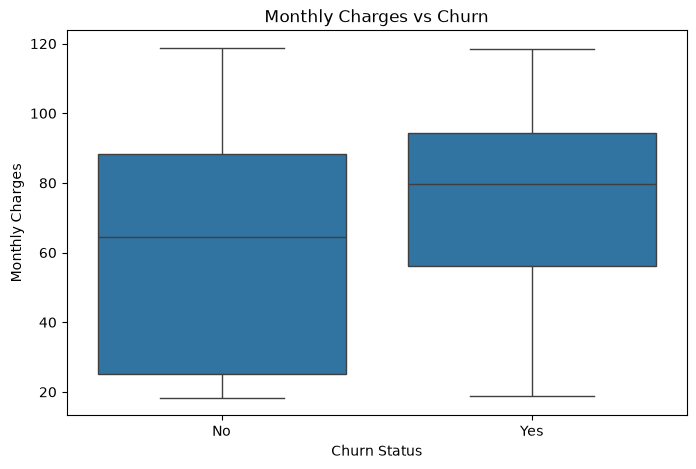

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()

In [26]:
df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "min", "max"]
).round(2)

,mean,median,min,max
Churn,,,,
No,61.27,64.43,18.25,118.75
Yes,74.44,79.65,18.85,118.35


### Monthly Charges vs Churn

Observations:

1. Customers who churn have a higher average
   monthly charge of 74.44.

2. Customers who do not churn have an average
   monthly charge of 61.27.

3. Median monthly charges are also higher
   for churned customers (79.65).

4. Higher monthly charges may be associated
   with increased customer churn.

Business Insights:

- High-paying customers may need special attention.
- The company should investigate pricing satisfaction.
- Suitable plans and discounts may help improve retention.

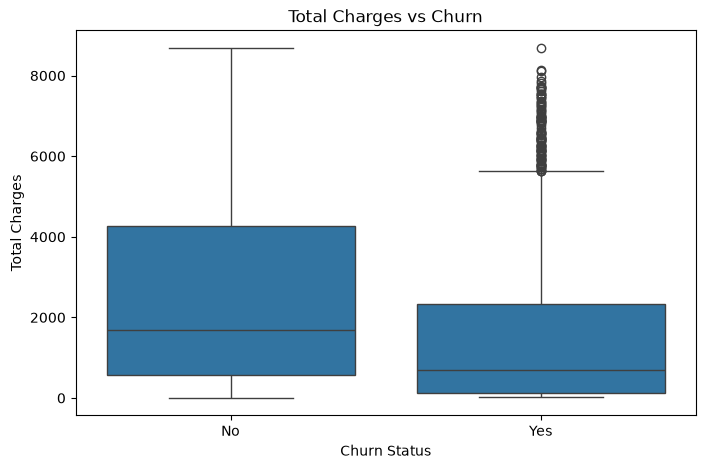

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Total Charges vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Total Charges")

plt.show()

In [28]:
df.groupby("Churn")["TotalCharges"].agg(
    ["mean", "median", "min", "max"]
).round(2)

,mean,median,min,max
Churn,,,,
No,2549.91,1679.52,0.00,8672.45
Yes,1531.80,703.55,18.85,8684.80


### Total Charges vs Churn

Observations:

1. Customers who churn have a lower average
   Total Charges of 1531.80.

2. Customers who do not churn have an average
   Total Charges of 2549.91.

3. Median Total Charges are lower for churned
   customers (703.55).

4. Churned customers generally have lower
   total spending.

Business Insights:

- Customers with lower total spending may have
  shorter relationships with the company.
- The company should focus on retaining new customers.
- Early customer engagement may help improve retention.

In [29]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

senior_churn.round(2)

Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


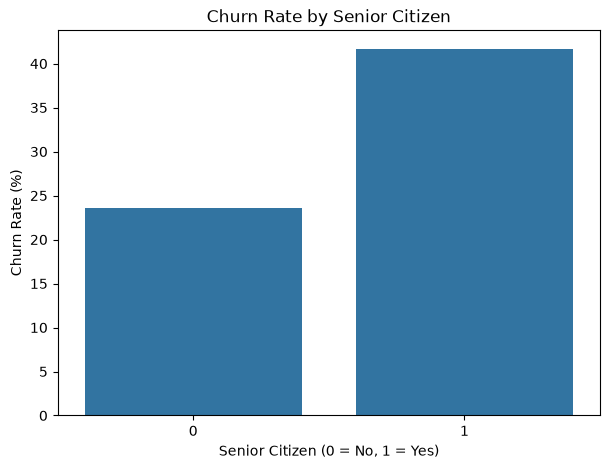

In [30]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=senior_churn.index,
    y=senior_churn["Yes"]
)

plt.title("Churn Rate by Senior Citizen")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")

plt.show()

### Senior Citizen vs Churn

Observations:

1. Non-senior citizens have a churn rate of 23.61%.

2. Senior citizens have a churn rate of 41.68%.

3. Senior citizens show a considerably higher
   churn rate compared to non-senior citizens.

Business Insights:

- Senior customers may require better customer support.
- The company should investigate their service
  satisfaction and retention needs.
- Targeted retention strategies may help reduce churn.

In [31]:
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

security_churn.round(2)

Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


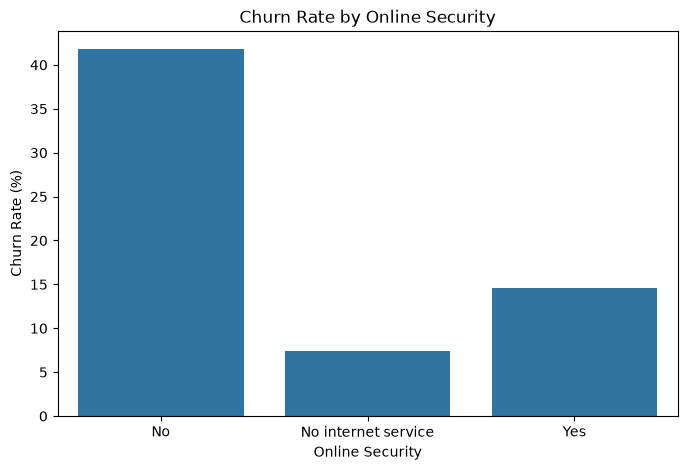

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=security_churn.index,
    y=security_churn["Yes"]
)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")

plt.show()

### Online Security vs Churn

Observations:

1. Customers without Online Security have a
   churn rate of 41.77%.

2. Customers with Online Security have a
   churn rate of 14.61%.

3. Customers without internet service have
   a churn rate of 7.40%.

Business Insights:

- Customers without Online Security show
  higher churn.
- The company can investigate whether
  additional security services improve retention.
- Suitable service bundles may help retain customers.

In [33]:
tech_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

tech_churn.round(2)

Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


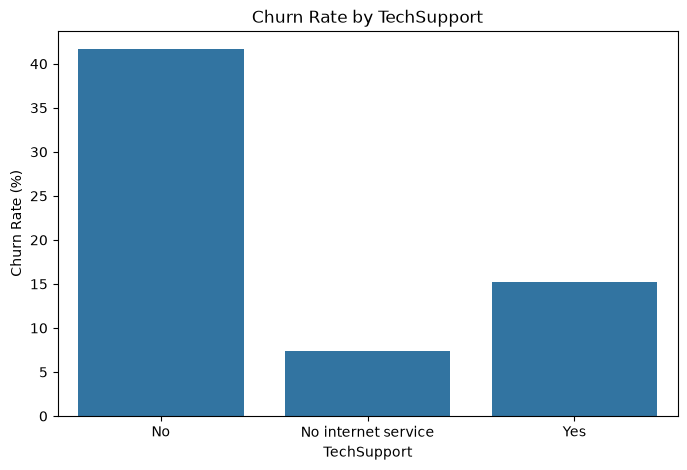

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=tech_churn.index,
    y=tech_churn["Yes"]
)

plt.title("Churn Rate by TechSupport")
plt.xlabel("TechSupport")
plt.ylabel("Churn Rate (%)")

plt.show()

### TechSupport vs Churn

Observations:

1. Customers without TechSupport have a churn
   rate of 41.64%.

2. Customers with TechSupport have a churn
   rate of 15.17%.

3. Customers without internet service have
   a churn rate of 7.40%.

Business Insights:

- Customers without technical support show
  higher churn.
- The company should improve technical
  support availability.
- Better customer support may help improve retention.

In [35]:
backup_churn = pd.crosstab(
    df["OnlineBackup"],
    df["Churn"],
    normalize="index"
) * 100

backup_churn.round(2)

Churn,No,Yes
OnlineBackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53


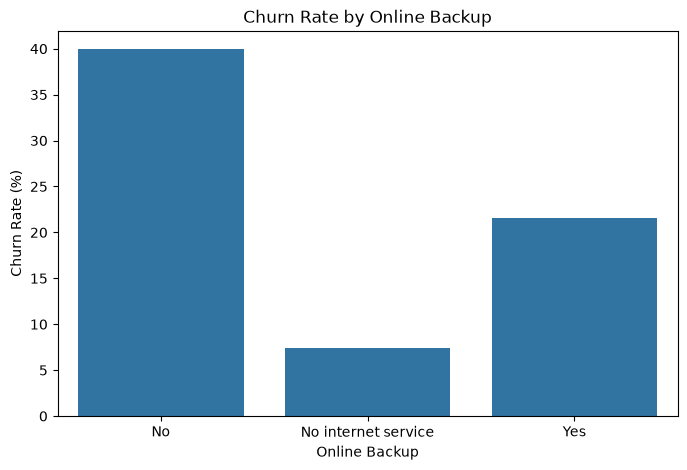

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=backup_churn.index,
    y=backup_churn["Yes"]
)

plt.title("Churn Rate by Online Backup")
plt.xlabel("Online Backup")
plt.ylabel("Churn Rate (%)")

plt.show()

### OnlineBackup vs Churn

Observations:

1. Customers without OnlineBackup have a churn
   rate of 39.93%.

2. Customers with OnlineBackup have a churn
   rate of 21.53%.

3. Customers without internet service have
   a churn rate of 7.40%.

Business Insights:

- Customers without OnlineBackup show higher churn.
- The company can investigate the demand for
  backup services.
- Suitable service bundles may improve retention.

In [37]:
device_churn = pd.crosstab(
    df["DeviceProtection"],
    df["Churn"],
    normalize="index"
) * 100

device_churn.round(2)

Churn,No,Yes
DeviceProtection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50


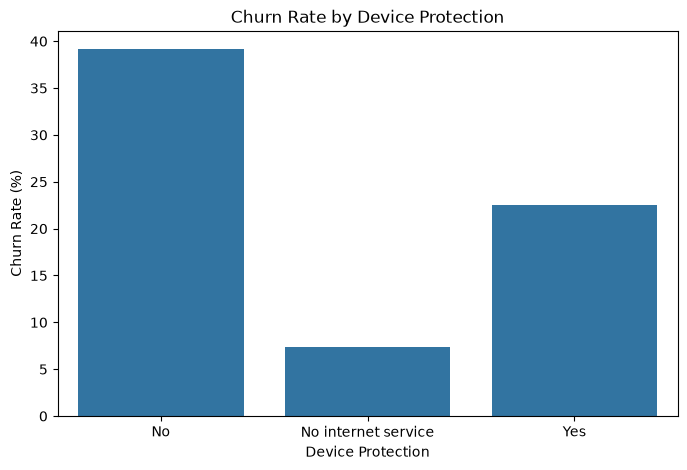

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=device_churn.index,
    y=device_churn["Yes"]
)

plt.title("Churn Rate by Device Protection")
plt.xlabel("Device Protection")
plt.ylabel("Churn Rate (%)")

plt.show()

### DeviceProtection vs Churn

Observations:

1. Customers without DeviceProtection have a
   churn rate of 39.13%.

2. Customers with DeviceProtection have a
   churn rate of 22.50%.

3. Customers without internet service have
   a churn rate of 7.40%.

Business Insights:

- Customers without DeviceProtection show
  higher churn.
- The company should investigate customer
  requirements for device protection.
- Suitable service packages may improve retention.

In [39]:
paperless_churn = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

paperless_churn.round(2)

Churn,No,Yes
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57


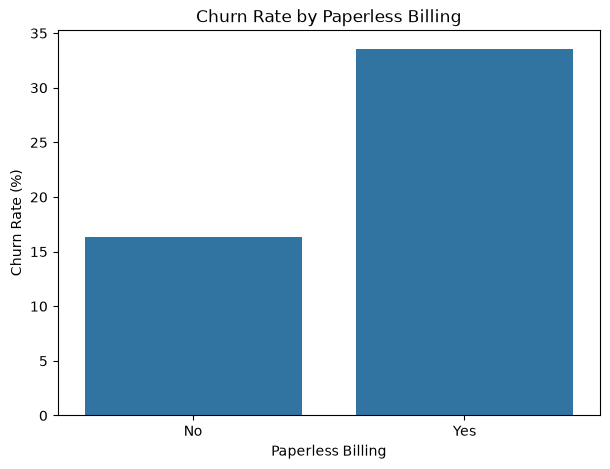

In [40]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=paperless_churn.index,
    y=paperless_churn["Yes"]
)

plt.title("Churn Rate by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Churn Rate (%)")

plt.show()

### PaperlessBilling vs Churn

Observations:

1. Customers using PaperlessBilling have a
   churn rate of 33.57%.

2. Customers not using PaperlessBilling have
   a churn rate of 16.33%.

3. PaperlessBilling users show a higher
   churn rate.

Business Insights:

- The company should investigate the payment
  experience of paperless billing users.
- Billing-related complaints should be monitored.
- Better billing communication may improve retention.

In [41]:
streaming_tv_churn = pd.crosstab(
    df["StreamingTV"],
    df["Churn"],
    normalize="index"
) * 100

streaming_tv_churn.round(2)

Churn,No,Yes
StreamingTV,,
No,66.48,33.52
No internet service,92.60,7.40
Yes,69.93,30.07


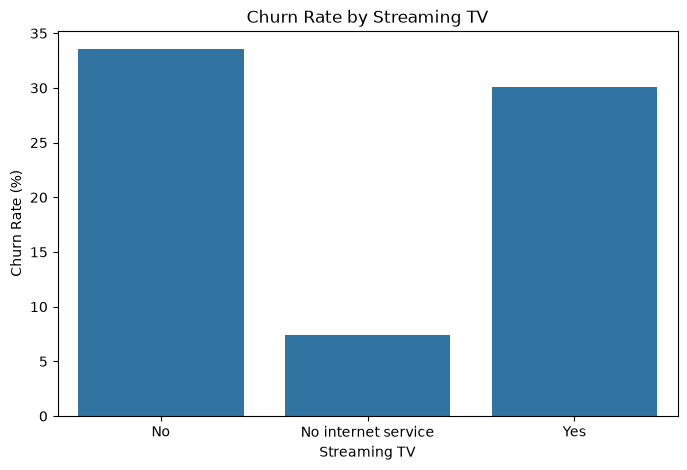

In [42]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=streaming_tv_churn.index,
    y=streaming_tv_churn["Yes"]
)

plt.title("Churn Rate by Streaming TV")
plt.xlabel("Streaming TV")
plt.ylabel("Churn Rate (%)")

plt.show()

### StreamingTV vs Churn

Observations:

1. Customers without StreamingTV have a churn
   rate of 33.52%.

2. Customers with StreamingTV have a churn
   rate of 30.07%.

3. Both categories show relatively similar
   churn rates.

4. Customers without internet service have
   a churn rate of 7.40%.

Business Insights:

- StreamingTV alone may not be a strong
  indicator of customer churn.
- Other customer service and contract features
  may have a stronger relationship with churn.

In [43]:
streaming_movies_churn = pd.crosstab(
    df["StreamingMovies"],
    df["Churn"],
    normalize="index"
) * 100

streaming_movies_churn.round(2)

Churn,No,Yes
StreamingMovies,,
No,66.32,33.68
No internet service,92.60,7.40
Yes,70.06,29.94


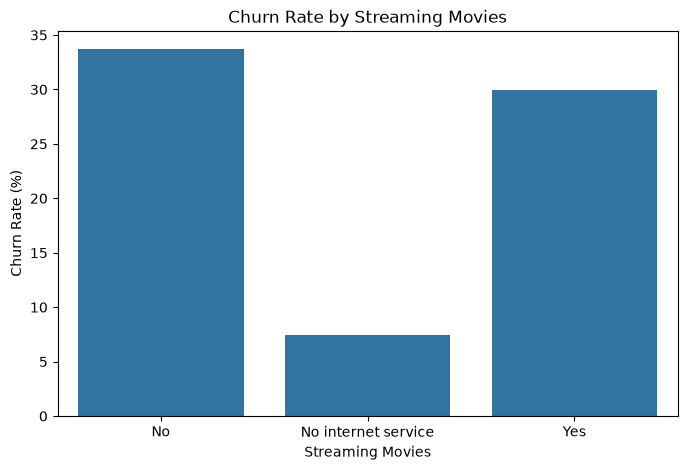

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=streaming_movies_churn.index,
    y=streaming_movies_churn["Yes"]
)

plt.title("Churn Rate by Streaming Movies")
plt.xlabel("Streaming Movies")
plt.ylabel("Churn Rate (%)")

plt.show()

### StreamingMovies vs Churn

Observations:

1. Customers without StreamingMovies have a
   churn rate of 33.68%.

2. Customers with StreamingMovies have a
   churn rate of 29.94%.

3. Both categories show relatively similar
   churn rates.

4. Customers without internet service have
   a churn rate of 7.40%.

Business Insights:

- StreamingMovies alone may not be a strong
  churn indicator.
- Other features such as Contract, Tenure,
  TechSupport and MonthlyCharges may provide
  more useful predictive information.

In [45]:
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

partner_churn.round(2)

Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


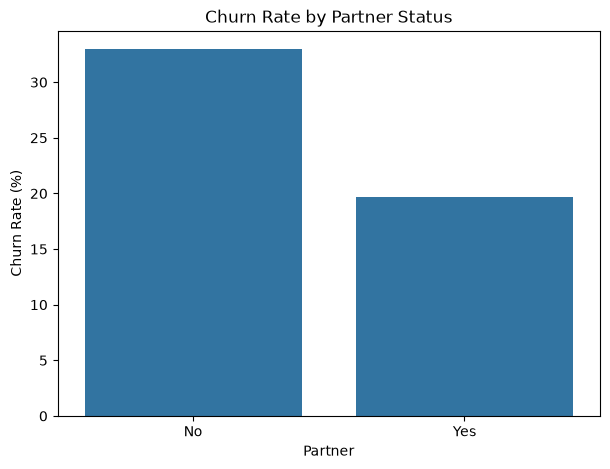

In [46]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=partner_churn.index,
    y=partner_churn["Yes"]
)

plt.title("Churn Rate by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Churn Rate (%)")

plt.show()

### Partner vs Churn

Observations:

1. Customers without a partner have a churn
   rate of 32.96%.

2. Customers with a partner have a churn
   rate of 19.66%.

3. Customers with partners show a lower
   churn rate.

Business Insights:

- Customers without partners may require
  additional retention attention.
- The company should investigate customer
  engagement and satisfaction patterns.

In [47]:
dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

dependents_churn.round(2)

Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


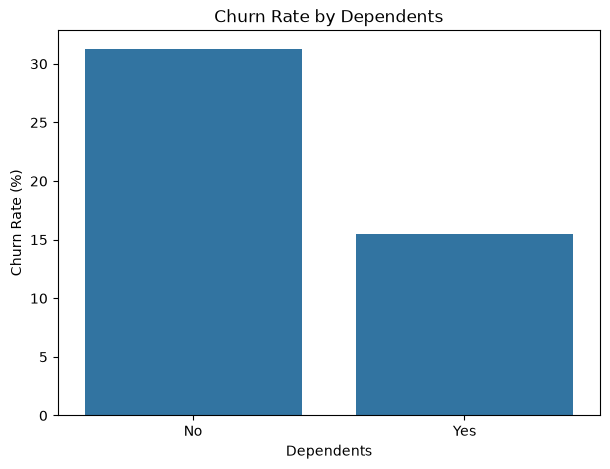

In [48]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=dependents_churn.index,
    y=dependents_churn["Yes"]
)

plt.title("Churn Rate by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Churn Rate (%)")

plt.show()

### Dependents vs Churn

Observations:

1. Customers without dependents have a churn
   rate of 31.28%.

2. Customers with dependents have a churn
   rate of 15.45%.

3. Customers with dependents show a lower
   churn rate.

Business Insights:

- Customers without dependents may need
  additional retention strategies.
- Customers with dependents show better
  customer retention.

In [49]:
gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

gender_churn.round(2)

Churn,No,Yes
gender,,
Female,73.08,26.92
Male,73.84,26.16


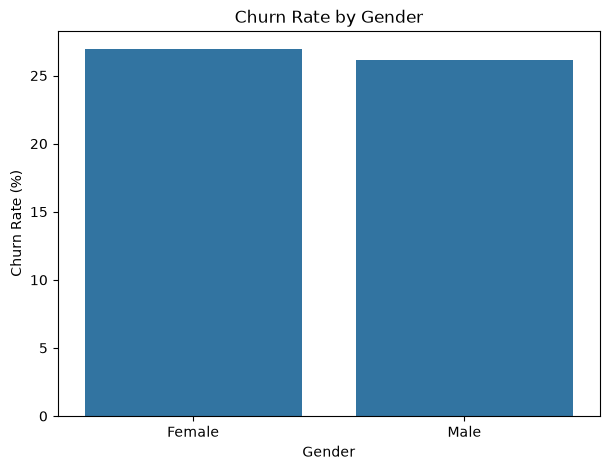

In [50]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_churn.index,
    y=gender_churn["Yes"]
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")

plt.show()

### Gender vs Churn

Observations:

1. Female customers have a churn rate of 26.92%.
2. Male customers have a churn rate of 26.16%.
3. Churn rates are almost similar for both genders.
4. Gender does not appear to be a strong churn indicator.

Business Insight:

Customer retention strategies should not be
based on gender alone.

In [51]:
phone_churn = pd.crosstab(
    df["PhoneService"],
    df["Churn"],
    normalize="index"
) * 100

phone_churn.round(2)

Churn,No,Yes
PhoneService,,
No,75.07,24.93
Yes,73.29,26.71


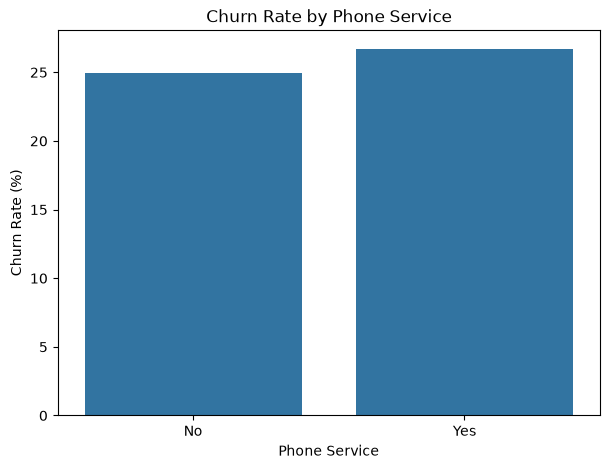

In [52]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=phone_churn.index,
    y=phone_churn["Yes"]
)

plt.title("Churn Rate by Phone Service")
plt.xlabel("Phone Service")
plt.ylabel("Churn Rate (%)")

plt.show()

In [53]:
multiplelines_churn = pd.crosstab(
    df["MultipleLines"],
    df["Churn"],
    normalize="index"
) * 100

multiplelines_churn.round(2)

Churn,No,Yes
MultipleLines,,
No,74.96,25.04
No phone service,75.07,24.93
Yes,71.39,28.61


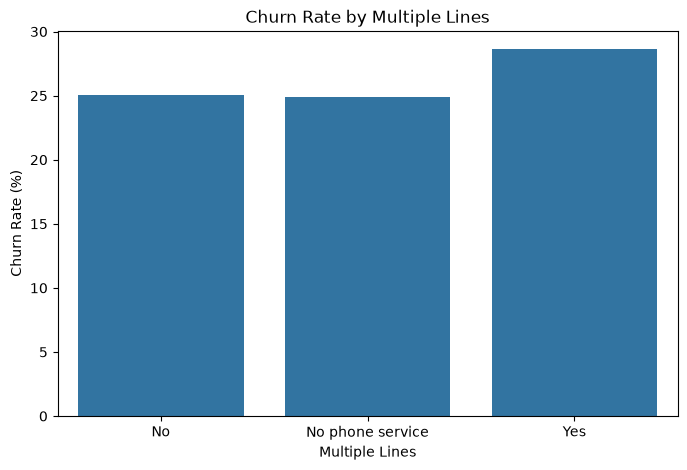

In [54]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=multiplelines_churn.index,
    y=multiplelines_churn["Yes"]
)

plt.title("Churn Rate by Multiple Lines")
plt.xlabel("Multiple Lines")
plt.ylabel("Churn Rate (%)")

plt.show()

In [55]:
onlinebackup_churn = pd.crosstab(
    df["OnlineBackup"],
    df["Churn"],
    normalize="index"
) * 100

onlinebackup_churn.round(2)

Churn,No,Yes
OnlineBackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53


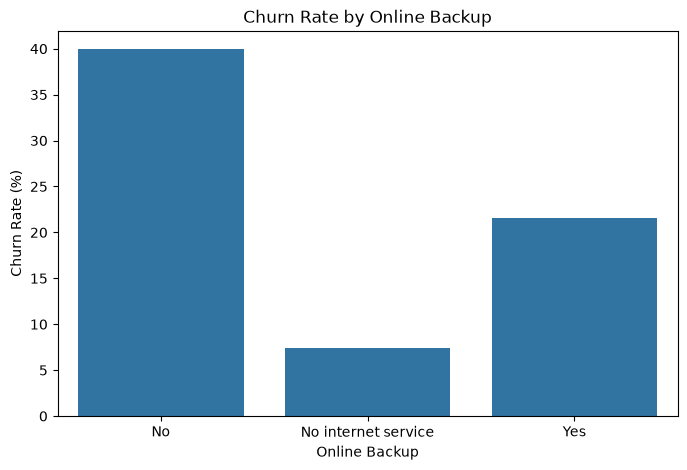

In [56]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=onlinebackup_churn.index,
    y=onlinebackup_churn["Yes"]
)

plt.title("Churn Rate by Online Backup")
plt.xlabel("Online Backup")
plt.ylabel("Churn Rate (%)")

plt.show()

In [57]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [58]:
corr = df.select_dtypes(include=np.number).corr()

corr.round(2)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
SeniorCitizen,1.00,0.02,0.22,0.10,0.15
tenure,0.02,1.00,0.25,0.83,-0.35
MonthlyCharges,0.22,0.25,1.00,0.65,0.19
TotalCharges,0.10,0.83,0.65,1.00,-0.20
Churn,0.15,-0.35,0.19,-0.20,1.00


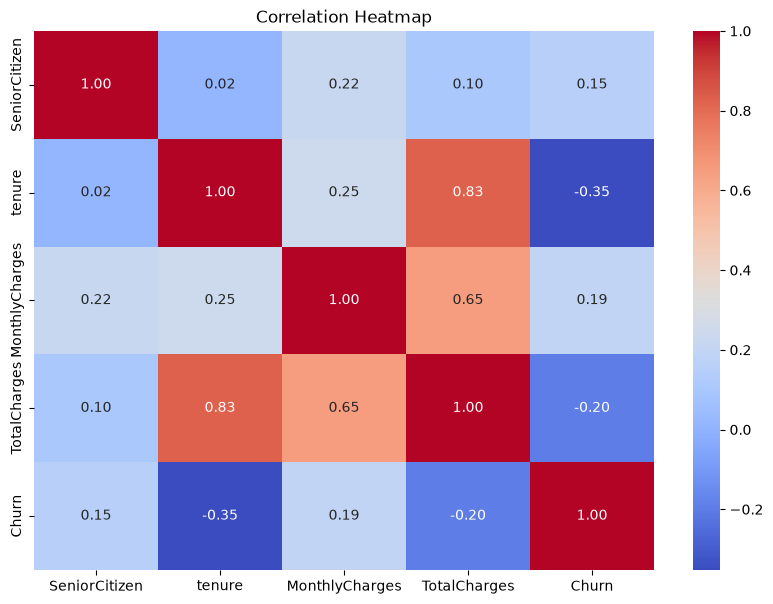

In [59]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

### Correlation Analysis - Observations

1. Tenure has the strongest negative correlation with Churn (-0.35).
2. MonthlyCharges has a weak positive correlation with Churn (0.19).
3. TotalCharges has a weak negative correlation with Churn (-0.20).
4. SeniorCitizen has a weak positive correlation with Churn (0.15).
5. Tenure and TotalCharges have a strong positive correlation (0.83).

### Conclusion

Customer tenure plays an important role in customer retention.
Customers with shorter tenure are generally more likely to churn.

In [60]:
cat_cols = df.select_dtypes(include="object").columns

print("Categorical Columns:")
print(cat_cols)

print("\nUnique Values:")
print(df[cat_cols].nunique())

Categorical Columns:
Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod'],
      dtype='str')

Unique Values:
customerID          7043
gender                 2
Partner                2
Dependents             2
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
dtype: int64


C:\Users\Mrinal Dutta\AppData\Local\Temp\ipykernel_7668\1520523724.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


In [61]:
cat_cols = df.select_dtypes(include="str").columns

cat_cols = cat_cols.drop("customerID", errors="ignore")

print("Total Categorical Features:", len(cat_cols))
print(cat_cols)

Total Categorical Features: 15
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')


In [62]:
for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].unique())


gender:
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

Partner:
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

Dependents:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

PhoneService:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

MultipleLines:
<ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

InternetService:
<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

OnlineSecurity:
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

OnlineBackup:
<ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

DeviceProtection:
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

TechSupport:
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

StreamingTV:
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

StreamingMovies:
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length

In [63]:
X = df.drop(
    columns=["Churn", "customerID"]
)

y = df["Churn"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (7043, 20)
y Shape: (7043,)


In [64]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 20)
X_test: (1409, 20)
y_train: (5634,)
y_test: (1409,)


In [65]:
X_train = pd.get_dummies(
    X_train,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    drop_first=True,
    dtype=int
)

X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

X_train Shape: (5634, 33)
X_test Shape: (1409, 33)


In [66]:
X_train.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_13-24 Months,TenureGroup_25-48 Months,TenureGroup_49-72 Months
3738,0,35,49.20,1701.65,1,0,0,0,1,0,...,1,0,0,0,0,1,0,0,1,0
3151,0,15,75.10,1151.55,1,1,1,1,0,0,...,0,0,0,0,0,0,1,1,0,0
4860,0,13,40.55,590.35,1,1,1,0,1,0,...,0,0,1,0,0,0,1,1,0,0
3867,0,26,73.50,1905.70,0,1,0,1,0,0,...,1,0,1,1,1,0,0,0,1,0
3810,0,1,44.55,44.55,1,1,1,1,0,0,...,0,0,0,0,0,1,0,0,0,0


In [67]:
num_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

In [68]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(
    X_train[num_cols]
)

X_test[num_cols] = scaler.transform(
    X_test[num_cols]
)

In [69]:
X_train[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.32,-1.54,-1.01
25%,-0.96,-0.97,-0.83
50%,-0.14,0.18,-0.40
75%,0.92,0.83,0.67
max,1.61,1.79,2.80


In [70]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(X_train, y_train)

print("Model Training Completed Successfully")

Model Training Completed Successfully


In [71]:
y_pred = model.predict(X_test)

print("Predictions:", y_pred[:10])

Predictions: [0 1 0 0 0 1 0 0 0 0]


In [72]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 79.91 %


In [73]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[932 103]
 [180 194]]


In [74]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [75]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(roc_auc, 3))

ROC-AUC Score: 0.842


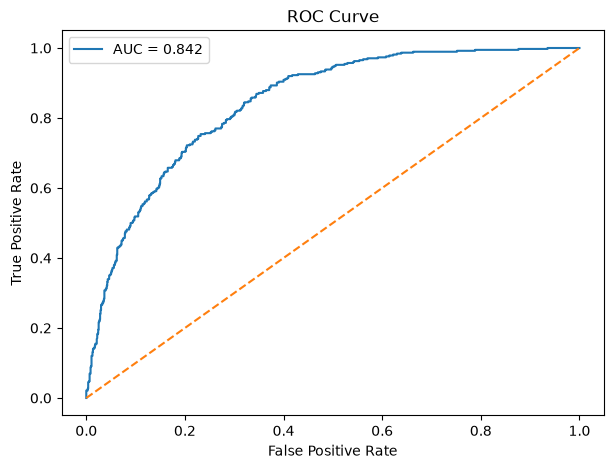

In [76]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")
plt.legend()

plt.show()

In [77]:
model2 = LogisticRegression(
    class_weight="balanced",
    random_state=42
)

model2.fit(X_train, y_train)

print("Balanced Model Training Completed")

Balanced Model Training Completed


In [78]:
y_pred2 = model2.predict(X_test)

print("Balanced Model Predictions:", y_pred2[:10])

Balanced Model Predictions: [0 1 0 1 0 1 1 0 0 1]


In [79]:
print("Balanced Model Classification Report:\n")

print(classification_report(y_test, y_pred2))

Balanced Model Classification Report:

              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1035
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409



In [80]:
cm2 = confusion_matrix(y_test, y_pred2)

print("Balanced Model Confusion Matrix:")
print(cm2)

Balanced Model Confusion Matrix:
[[736 299]
 [ 78 296]]


In [81]:
y_prob2 = model2.predict_proba(X_test)[:, 1]

roc_auc2 = roc_auc_score(y_test, y_prob2)

print("Balanced Model ROC-AUC:", round(roc_auc2, 3))

Balanced Model ROC-AUC: 0.842


In [82]:
model_comparison = pd.DataFrame({
    "Model": ["Normal Logistic Regression", "Balanced Logistic Regression"],
    "Accuracy": [accuracy_score(y_test, y_pred),
                 accuracy_score(y_test, y_pred2)],
    "Precision": [
        classification_report(y_test, y_pred, output_dict=True)["1"]["precision"],
        classification_report(y_test, y_pred2, output_dict=True)["1"]["precision"]
    ],
    "Recall": [
        classification_report(y_test, y_pred, output_dict=True)["1"]["recall"],
        classification_report(y_test, y_pred2, output_dict=True)["1"]["recall"]
    ],
    "F1-Score": [
        classification_report(y_test, y_pred, output_dict=True)["1"]["f1-score"],
        classification_report(y_test, y_pred2, output_dict=True)["1"]["f1-score"]
    ],
    "ROC-AUC": [roc_auc, roc_auc2]
})

model_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Normal Logistic Regression,0.799,0.653,0.519,0.578,0.842
1,Balanced Logistic Regression,0.732,0.497,0.791,0.611,0.842


In [83]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model2.coef_[0]
})

feature_importance["Abs_Importance"] = (
    feature_importance["Importance"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Abs_Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance,Abs_Importance
25,Contract_Two year,-1.525876,1.525876
10,InternetService_Fiber optic,1.194949,1.194949
1,tenure,-1.025683,1.025683
24,Contract_One year,-0.731846,0.731846
2,MonthlyCharges,-0.423527,0.423527
23,StreamingMovies_Yes,0.420365,0.420365
30,TenureGroup_13-24 Months,-0.402380,0.402380
21,StreamingTV_Yes,0.397898,0.397898
28,PaymentMethod_Electronic check,0.393597,0.393597
9,MultipleLines_Yes,0.355390,0.355390


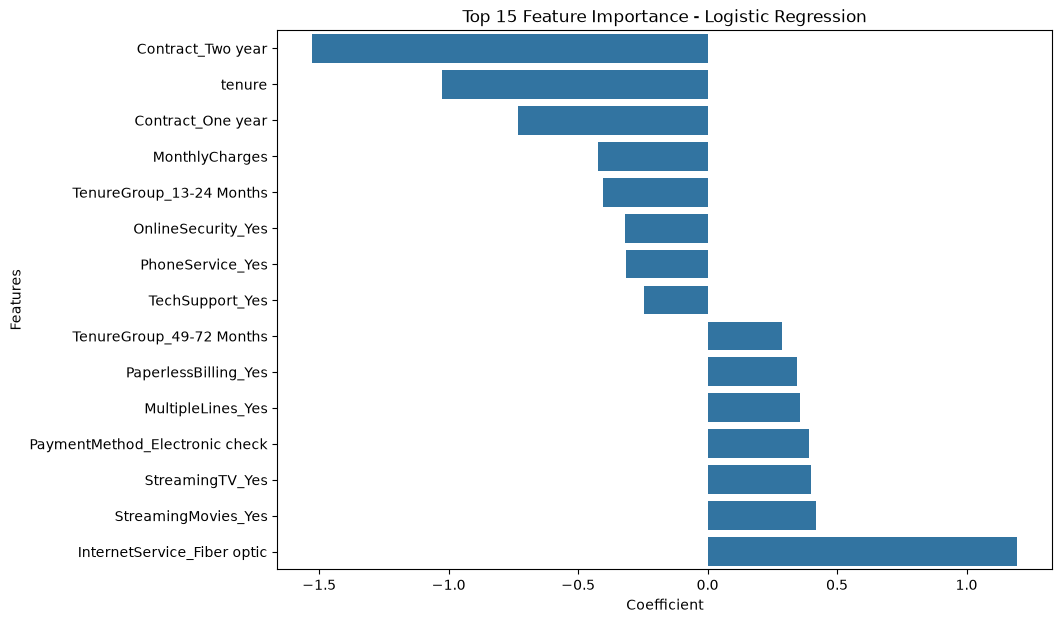

In [84]:
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importance - Logistic Regression")
plt.xlabel("Coefficient")
plt.ylabel("Features")

plt.show()

## Business Insights & Recommendations

### Key Findings
- Customers with month-to-month contracts have higher churn rates.
- Customers with shorter tenure are more likely to leave.
- Electronic check users show higher churn.
- Fiber optic users have relatively higher churn.
- Customers without online security and tech support show higher churn.

### Business Recommendations
- Encourage customers to choose long-term contracts.
- Provide special offers to new customers.
- Improve fiber optic service quality.
- Promote automatic payment methods.
- Offer online security and technical support services.

### Final Conclusion
This project identifies important factors affecting customer churn using Exploratory Data Analysis and Machine Learning.

Logistic Regression was used to predict customer churn. Class balancing improved churn detection recall from approximately 52% to 79%.

The analysis can help businesses identify customers at risk of leaving and develop better customer retention strategies.

In [85]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

dt_model.fit(X_train, y_train)

print("Decision Tree Training Completed")

Decision Tree Training Completed


In [86]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

# Prediction
y_pred_dt = dt_model.predict(X_test)

# Probability prediction
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

# Model evaluation
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob_dt))

Accuracy: 0.7281760113555713

Confusion Matrix:
 [[846 189]
 [194 180]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.82      0.82      1035
           1       0.49      0.48      0.48       374

    accuracy                           0.73      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.73      0.73      0.73      1409

ROC-AUC Score: 0.6498023715415019


In [87]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest Training Completed")

Random Forest Training Completed


In [88]:
# Prediction
y_pred_rf = rf_model.predict(X_test)

# Probability prediction
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Model Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

print("ROC-AUC Score:", roc_auc_score(y_test, y_prob_rf))

Accuracy: 0.7665010645848119

Confusion Matrix:
 [[843 192]
 [137 237]]

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.81      0.84      1035
           1       0.55      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.71      1409
weighted avg       0.78      0.77      0.77      1409

ROC-AUC Score: 0.8265106306027021


In [89]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Logistic Regression": (model, y_pred),
    "Balanced Logistic Regression": (model2, y_pred2),
    "Decision Tree": (dt_model, y_pred_dt),
    "Random Forest": (rf_model, y_pred_rf)
}

comparison = []

for name, (trained_model, predictions) in models.items():
    probabilities = trained_model.predict_proba(X_test)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

model_comparison = pd.DataFrame(comparison)

model_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.799,0.653,0.519,0.578,0.842
1,Balanced Logistic Regression,0.732,0.497,0.791,0.611,0.842
2,Decision Tree,0.728,0.488,0.481,0.485,0.650
3,Random Forest,0.767,0.552,0.634,0.590,0.827


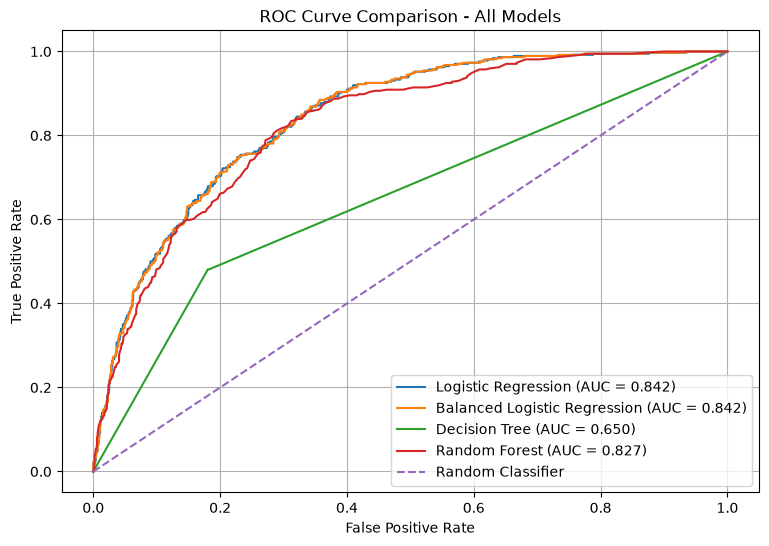

In [90]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

models_for_roc = {
    "Logistic Regression": model,
    "Balanced Logistic Regression": model2,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

plt.figure(figsize=(9, 6))

for name, trained_model in models_for_roc.items():
    y_prob = trained_model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - All Models")
plt.legend()
plt.grid()
plt.show()

In [91]:
feature_importance_rf = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance_rf = feature_importance_rf.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_rf.head(15)

,Feature,Importance
3,TotalCharges,0.164580
2,MonthlyCharges,0.147625
1,tenure,0.144463
25,Contract_Two year,0.050031
10,InternetService_Fiber optic,0.046332
28,PaymentMethod_Electronic check,0.037906
32,TenureGroup_49-72 Months,0.031888
24,Contract_One year,0.028134
4,gender_Male,0.025925
26,PaperlessBilling_Yes,0.025139


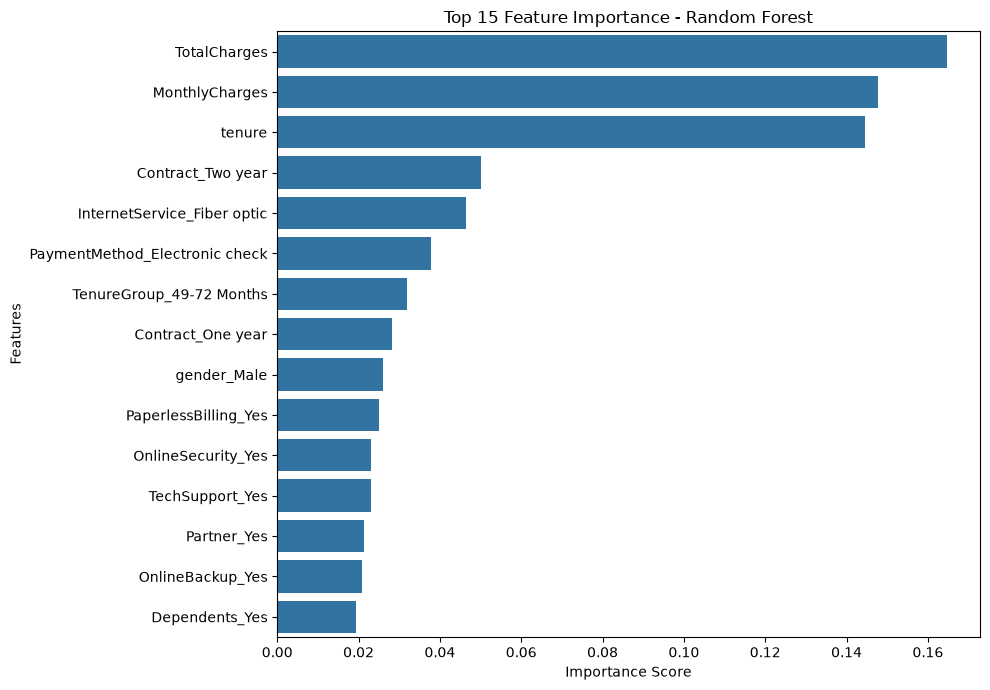

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = feature_importance_rf.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## Random Forest Feature Importance - Key Insights

### Key Findings
- TotalCharges is the most important feature.
- MonthlyCharges and tenure also play significant roles.
- Contract type contributes to churn prediction.
- Internet service type provides useful predictive information.
- Customer billing and service-related features help the model identify churn patterns.

### Business Implications
- Monitor customers with high monthly charges.
- Focus on improving customer retention during early tenure.
- Encourage customers to choose long-term contracts.
- Review service quality and customer satisfaction for fiber optic users.

### Conclusion
Random Forest feature importance highlights billing, customer tenure, and contract-related information as important predictors of customer churn.

In [93]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_prob = model2.predict_proba(X_test)[:, 1]

thresholds = [0.3, 0.4, 0.5, 0.6]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1 Score": f1_score(y_test, y_pred_threshold)
    })

threshold_comparison = pd.DataFrame(threshold_results)

threshold_comparison.round(3)

,Threshold,Precision,Recall,F1 Score
0,0.3,0.427,0.925,0.584
1,0.4,0.473,0.874,0.614
2,0.5,0.497,0.791,0.611
3,0.6,0.558,0.711,0.625


In [94]:
from sklearn.metrics import confusion_matrix, classification_report

best_threshold = 0.4

y_pred_tuned = (y_prob >= best_threshold).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

Confusion Matrix:
[[670 365]
 [ 47 327]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.65      0.76      1035
           1       0.47      0.87      0.61       374

    accuracy                           0.71      1409
   macro avg       0.70      0.76      0.69      1409
weighted avg       0.81      0.71      0.72      1409



In [95]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\ny_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5634, 33)
X_test shape: (1409, 33)

y_train shape: (5634,)
y_test shape: (1409,)


In [96]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training Data:", X_train_final.shape)
print("Validation Data:", X_val.shape)

print("Training Target:", y_train_final.shape)
print("Validation Target:", y_val.shape)

Training Data: (4507, 33)
Validation Data: (1127, 33)
Training Target: (4507,)
Validation Target: (1127,)


In [97]:
model_final = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

model_final.fit(X_train_final, y_train_final)

print("Final Logistic Regression Model Trained Successfully")

Final Logistic Regression Model Trained Successfully


In [98]:
y_val_prob = model_final.predict_proba(X_val)[:, 1]

print("Validation Predictions Generated")
print("Total Predictions:", len(y_val_prob))

Validation Predictions Generated
Total Predictions: 1127


In [99]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

validation_results = []

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    validation_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1 Score": f1_score(y_val, y_val_pred)
    })

validation_comparison = pd.DataFrame(validation_results)

validation_comparison.round(3)

,Threshold,Precision,Recall,F1 Score
0,0.3,0.417,0.913,0.572
1,0.4,0.468,0.860,0.606
2,0.5,0.519,0.776,0.622
3,0.6,0.578,0.719,0.641
4,0.7,0.677,0.595,0.633


In [100]:
best_threshold = 0.6

final_model = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

final_model.fit(X_train, y_train)

print("Final Model Trained on Full Training Data")

Final Model Trained on Full Training Data


In [101]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Test data probabilities
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_test_final = (y_test_prob >= best_threshold).astype(int)

# Evaluation
print("Final Threshold:", best_threshold)

print("\nAccuracy:", accuracy_score(y_test, y_test_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_final))

print("\nClassification Report:")
print(classification_report(y_test, y_test_final))

print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))

Final Threshold: 0.6

Accuracy: 0.7735982966643009

Confusion Matrix:
[[824 211]
 [108 266]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.80      0.84      1035
           1       0.56      0.71      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409

ROC-AUC: 0.8421994884910485


## Final Model Evaluation

### Selected Model
Balanced Logistic Regression

### Selected Threshold
0.6 (selected using validation data based on F1-score)

### Final Test Performance
- Accuracy: 77.36%
- Precision: 56%
- Recall: 71%
- F1-Score: 63%
- ROC-AUC: 0.842

### Business Interpretation
The final model successfully identifies approximately 71% of actual churn customers.

This model can help businesses identify customers who are at risk of leaving and take proactive retention measures.

### Final Conclusion
Balanced Logistic Regression was selected based on validation F1-score.

The final model achieved a ROC-AUC of 0.842 on the untouched test dataset, showing good ability to distinguish between churn and non-churn customers.

In [102]:
import os
import joblib

# Create models folder
os.makedirs("../models", exist_ok=True)

# Save model and required information
model_artifacts = {
    "model": final_model,
    "scaler": scaler,
    "feature_columns": X_train.columns.tolist(),
    "threshold": best_threshold,
    "numeric_columns": num_cols
}

# Save artifacts
joblib.dump(model_artifacts, "../models/customer_churn_model.pkl")

print("Model and preprocessing artifacts saved successfully!")

Model and preprocessing artifacts saved successfully!


In [103]:
# Load saved model
loaded_artifacts = joblib.load("../models/customer_churn_model.pkl")

# Extract model
loaded_model = loaded_artifacts["model"]

# Make predictions
sample_predictions = loaded_model.predict(X_test.head(5))

print("Loaded Model:", loaded_model)
print("Sample Predictions:", sample_predictions)

Loaded Model: LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
Sample Predictions: [0 1 0 1 0]


In [104]:
# Load selected threshold
loaded_threshold = loaded_artifacts["threshold"]

# Generate probabilities
sample_probabilities = loaded_model.predict_proba(X_test.head(5))[:, 1]

# Apply selected threshold
sample_predictions = (
    sample_probabilities >= loaded_threshold
).astype(int)

print("Selected Threshold:", loaded_threshold)
print("Probabilities:", sample_probabilities.round(3))
print("Final Predictions:", sample_predictions)

Selected Threshold: 0.6
Probabilities: [0.11  0.882 0.137 0.591 0.067]
Final Predictions: [0 1 0 0 0]


In [1]:
import os

print(os.getcwd())

C:\Users\Mrinal Dutta\Telco-Customer-Churn-Prediction\notebook
